# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.fm Decision Tree
*By Mark Lambert - C00192497 | [LinkedIn](https://www.linkedin.com/in/mark-lambert-27tw721921/) | [GitHub](https://github.com/lambert-27)* | [Personal Email](mailto:marklambert123@gmail.com)

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 27th November 2026*

*Start Date: 9th November 2026*

---

## Research question



In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

audio = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo', 'duration']

plays = pd.read_csv('../datasets/scrobbles.csv')
tracks = pd.read_csv('../datasets/scrobbled_merged_with_hugging_face.csv')

# one row per track
tracks = tracks.dropna(subset=['track_id'] + audio).drop_duplicates(subset='track_id')
print(len(tracks))

1838


Making a Decision Tree to predict the top four artists based on two features, `energy` and `acousticness`

['Portishead', 'Arctic Monkeys', 'Tame Impala', 'Red Hot Chili Peppers']


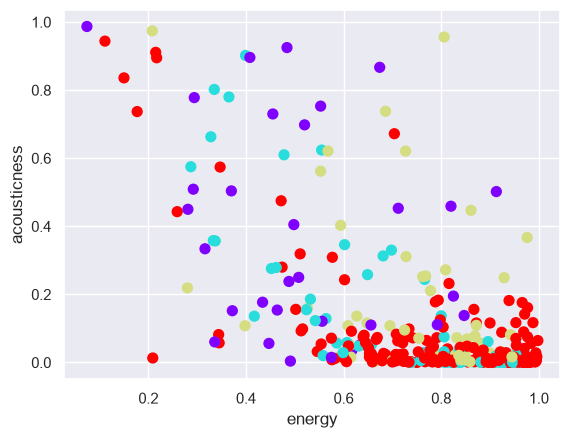

In [4]:
top4 = plays['artist'].value_counts().head(4).index
sub4 = tracks[tracks['artist'].isin(top4)]

X2 = sub4[['energy', 'acousticness']].values
y2, names4 = pd.factorize(sub4['artist'])

plt.scatter(X2[:, 0], X2[:, 1], c=y2, s=50, cmap='rainbow')
plt.xlabel('energy')
plt.ylabel('acousticness')
print(list(names4))

The top four artists by scrobbles are Portishead (purple), Arctic Monkeys (cyan), Tame Impala (yellow-green) and Red Hot Chili Peppers (red)

Portishead sits mostly at low energy and high acousticness, away from the others. The other three overlap in the corner with low acousticness, so these two features will not separate them well

Two features are used here only so the decision regions can be drawn

Using the example [handbook](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.08-Random-Forests.ipynb), I have pulled the `visuaalise_classsifier()` function

In [5]:
# visualization helper from the Handbook
def visualise_classifier(model, X, y, ax=None, cmap='rainbow'):
    ax = ax or plt.gca()

    # Plot the training points
    ax.scatter(X[:, 0], X[:, 1], c=y, s=30, cmap=cmap,
               clim=(y.min(), y.max()), zorder=3)
    ax.axis('tight')
    ax.axis('off')
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # fit the estimator
    model.fit(X, y)
    xx, yy = np.meshgrid(np.linspace(*xlim, num=200),
                         np.linspace(*ylim, num=200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Create a color plot with the results
    n_classes = len(np.unique(y))
    contours = ax.contourf(xx, yy, Z, alpha=0.3,
                           levels=np.arange(n_classes + 1) - 0.5,
                           cmap=cmap, zorder=1)

    ax.set(xlim=xlim, ylim=ylim)

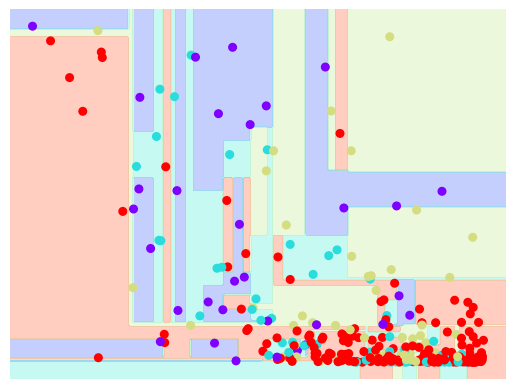

In [6]:
tree = DecisionTreeClassifier(random_state=0)
visualise_classifier(tree, X2, y2)

Each split in a decision tree is a threshold on one feature, so the regions are rectangles. This tree has no depth limit, so it keeps splitting until it fits the training points

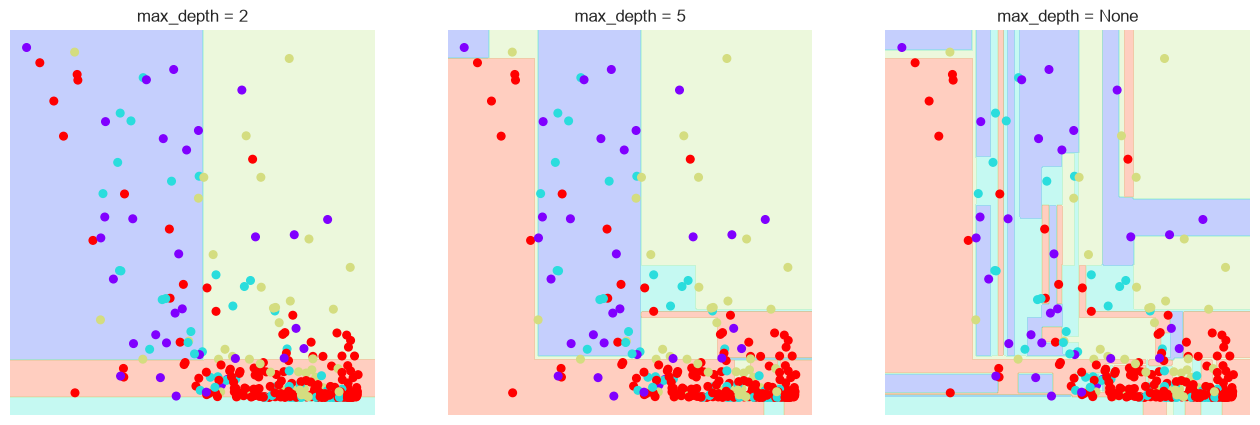

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, depth in zip(ax, [2, 5, None]):
    visualise_classifier(DecisionTreeClassifier(max_depth=depth, random_state=0), X2, y2, ax=a)
    a.set_title(f'max_depth = {depth}')

The same data at three depths. At `max_depth=2` the plane is split into a few large blocks. 5, the blocks are smaller and more fragmented, and with no limit the tree draws thin slivers around individual points in the crowded bottom corner

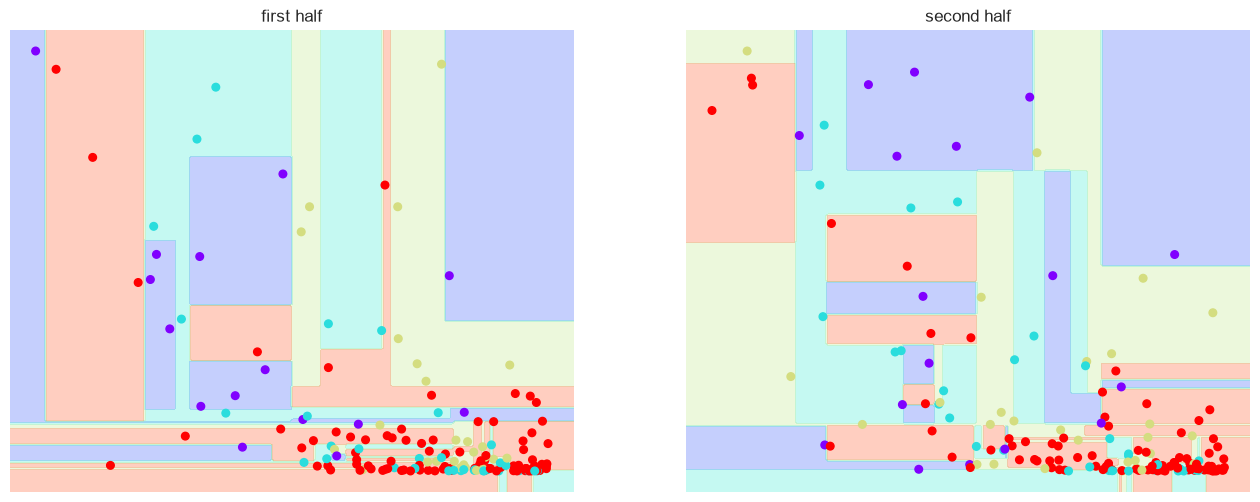

In [8]:
rng = np.random.RandomState(0)
idx = rng.permutation(len(X2))
half = len(X2) // 2
A, B = idx[:half], idx[half:]

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
visualise_classifier(DecisionTreeClassifier(random_state=0), X2[A], y2[A], ax=ax[0])
visualise_classifier(DecisionTreeClassifier(random_state=0), X2[B], y2[B], ax=ax[1])
ax[0].set_title('first half')
ax[1].set_title('second half');

Two trees trained on different halves of the same data

They have similar predictions on some large regions near the edges but disagree in the crowded corner, where the classes overlap

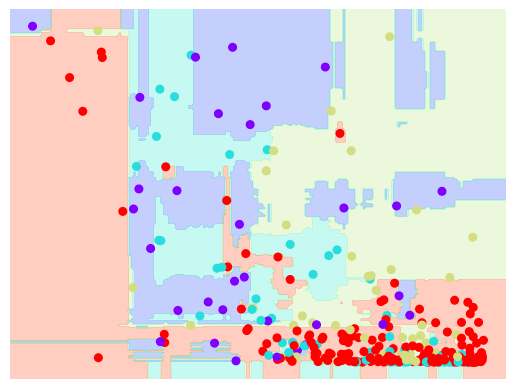

In [9]:
tree = DecisionTreeClassifier()
bag = BaggingClassifier(tree, n_estimators=100, max_samples=0.8,
                        random_state=1)

visualise_classifier(bag, X2, y2)

Bagging fits 100 trees, each on a random 80% of the tracks, and combines their predictions. The regions are smoother than a single tree's, because the odd slivers from one tree are outvoted by the others

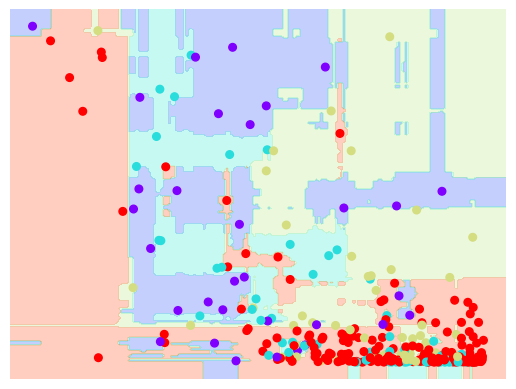

In [8]:
model = RandomForestClassifier(n_estimators=100, random_state=0)
visualise_classifier(model, X2, y2);

A random forest also randomises which features each split can use, here with 100 trees

The regions are rounder again, but the crowded bottom corner is still a lot of colours. Averaging trees reduces variance, but it doesnt separate artists whose tracks overlap on these two features